# Projeto final

Bem vindo ao projeto final do curso/módulo de Pandas.
Neste projeto, você deve responder a um conjunto de perguntas feitas a dois conjuntos de dados:

1. [Obesity among adults by country, 1975-2016](https://www.kaggle.com/amanarora/obesity-among-adults-by-country-19752016/)
2. [GDP Per Person (1901-2011)](https://www.kaggle.com/divyansh22/gdp-per-person-19012011?select=GDP.csv)

Tais conjuntos de dados são públicos foram publicados no Kaggle. Mais instruções sobre cada um deles podem ser encontrados nos links acima. Você também os encontrará na pasta `Datasets`, dentro de nossas apostilas.

In [5]:
import pandas as pd
import numpy as np

## Perguntas - Obesity among adults by country, 1975-2016

In [6]:
df_obesity = pd.read_csv("obesity_cleaned.csv")

- Limpe os dados do DataFrame, criando uma coluna de nome 'Obesity' que conterá os valores de obesidade. Transforme em float as colunas que porventura foram importadas como string.

In [7]:
df_obesity['Obesity (%)'].str.split(' ')

0           [0.5, [0.2-1.1]]
1           [0.2, [0.0-0.6]]
2           [0.8, [0.2-2.0]]
3           [0.5, [0.2-1.1]]
4           [0.2, [0.0-0.7]]
                ...         
24565       [4.5, [2.4-7.6]]
24566    [24.8, [18.9-31.3]]
24567    [15.5, [12.0-19.2]]
24568       [4.7, [2.5-8.0]]
24569    [25.3, [19.1-32.0]]
Name: Obesity (%), Length: 24570, dtype: object

In [8]:
df_obesity['Obesity (%)'].str.split(' ').str[0]

0         0.5
1         0.2
2         0.8
3         0.5
4         0.2
         ... 
24565     4.5
24566    24.8
24567    15.5
24568     4.7
24569    25.3
Name: Obesity (%), Length: 24570, dtype: object

In [9]:
df_obesity['Obesity'] = df_obesity['Obesity (%)'].str.split(' ').str[0]


In [10]:
df_obesity


,Unnamed: 0,Country,Year,Obesity (%),Sex,Obesity
0,0,Afghanistan,1975,0.5 [0.2-1.1],Both sexes,0.5
1,1,Afghanistan,1975,0.2 [0.0-0.6],Male,0.2
2,2,Afghanistan,1975,0.8 [0.2-2.0],Female,0.8
3,3,Afghanistan,1976,0.5 [0.2-1.1],Both sexes,0.5
4,4,Afghanistan,1976,0.2 [0.0-0.7],Male,0.2
...,...,...,...,...,...,...
24565,24565,Zimbabwe,2015,4.5 [2.4-7.6],Male,4.5
24566,24566,Zimbabwe,2015,24.8 [18.9-31.3],Female,24.8
24567,24567,Zimbabwe,2016,15.5 [12.0-19.2],Both sexes,15.5
24568,24568,Zimbabwe,2016,4.7 [2.5-8.0],Male,4.7


In [11]:
df_obesity['Obesity'] = pd.to_numeric(df_obesity['Obesity'], errors='coerce')

In [12]:
df_obesity['Obesity'].info()

<class 'pandas.Series'>
RangeIndex: 24570 entries, 0 to 24569
Series name: Obesity
Non-Null Count  Dtype  
--------------  -----  
24066 non-null  float64
dtypes: float64(1)
memory usage: 192.1 KB


- Qual o percentual médio de obesidade por sexo no mundo no ano de 2015?

In [13]:
obesity_2015 = df_obesity[df_obesity['Year'] == 2015]

In [14]:
obesity_2015.groupby('Sex')['Obesity'].mean()

Sex
Both sexes    19.508377
Female        22.899476
Male          15.980628
Name: Obesity, dtype: float64

- Quais são os 5 países com a maior e a menor taxa de aumento nos índices de obesidade no período observado?

In [15]:
ambos = df_obesity[df_obesity['Sex'] == 'Both sexes']

In [16]:
inicio = ambos[ambos['Year'] == 1975].set_index('Country')['Obesity']
fim = ambos[ambos['Year'] == 2016].set_index('Country')['Obesity']

In [17]:
aumento = (fim - inicio) / inicio * 100

In [18]:
aumento = aumento.replace([np.inf, -np.inf], np.nan).dropna()

In [19]:
aumento.sort_values(ascending=False).head(5)

Country
Viet Nam                            2000.000000
Timor-Leste                         1800.000000
Bangladesh                          1700.000000
Lao People's Democratic Republic    1666.666667
Indonesia                           1625.000000
Name: Obesity, dtype: float64

In [20]:
aumento.sort_values().head(5)

Country
Nauru                 37.078652
Russian Federation    66.187050
Estonia               66.929134
Latvia                76.119403
Malta                 85.256410
Name: Obesity, dtype: float64


- Quais os países com maiores e menores níveis percetuais de obesidade em 2015?

In [21]:
obs_2015  = ambos[ambos['Year'] == 2015].set_index('Country')['Obesity']

In [22]:
obs_2015.sort_values(ascending=False).head(5)

Country
Nauru               60.7
Cook Islands        55.4
Palau               54.8
Marshall Islands    52.4
Tuvalu              50.9
Name: Obesity, dtype: float64

In [23]:
obs_2015.sort_values().head(5)

Country
Viet Nam       2.0
Bangladesh     3.4
Timor-Leste    3.6
Cambodia       3.7
India          3.7
Name: Obesity, dtype: float64

- Qual a diferença média percentual de obesidade entre sexos ao longo dos anos para o Brasil?

In [24]:
df_obesity[df_obesity['Country'].str.contains('Bra')]['Country'].unique()

<StringArray>
['Brazil']
Length: 1, dtype: str

In [25]:
brasil = df_obesity[df_obesity['Country'] == 'Brazil']

In [26]:
mulheres = brasil[brasil['Sex'] == 'Female'].set_index('Year')['Obesity']
homens = brasil[brasil['Sex'] == 'Male'].set_index('Year')['Obesity']
diferenca = mulheres - homens
diferenca.mean()

np.float64(6.178571428571429)

- Você conseguiria plotar um gráfico mostrando a evolução da obesidade para ambos sexos no mundo?

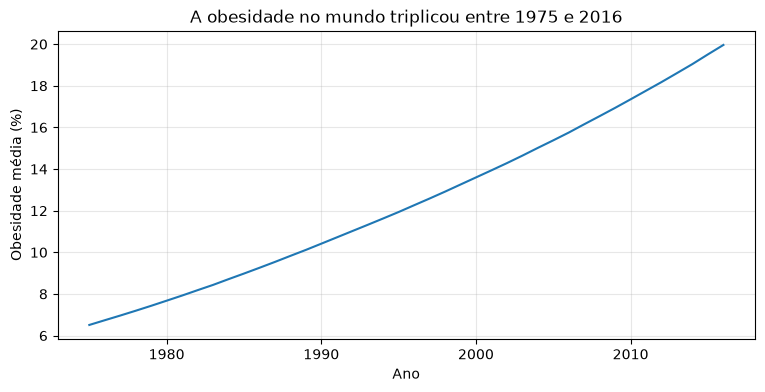

In [29]:
import matplotlib.pyplot as plt

df_both = ambos.groupby('Year')['Obesity'].mean()
df_both.plot(figsize=(9, 4))
plt.title('A obesidade no mundo triplicou entre 1975 e 2016')
plt.xlabel('Ano')
plt.ylabel('Obesidade média (%)')
plt.grid(alpha=0.3)
plt.show()

## Perguntas - GDP Per Person (1901-2011)

In [68]:
import pandas as pd
import numpy as np

In [69]:
df_gdp = pd.read_csv("gdp.csv", decimal=".")

- Limpe o conjunto de dados, convertendo strings em datas ou float, quando necessário.

In [70]:
df_gdp.info()

<class 'pandas.DataFrame'>
RangeIndex: 4419 entries, 0 to 4418
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Country   4419 non-null   str  
 1   Region    4419 non-null   str  
 2   Year      4419 non-null   str  
 3    GDP_pp   4419 non-null   str  
dtypes: str(4)
memory usage: 138.2 KB


In [71]:
df_gdp

,Country,Region,Year,GDP_pp
0,Afghanistan,"Middle East, North Africa, and Greater Arabia",1/1/1901,613.99
1,Afghanistan,"Middle East, North Africa, and Greater Arabia",1/1/1906,624.04
2,Afghanistan,"Middle East, North Africa, and Greater Arabia",1/1/1911,634.25
3,Afghanistan,"Middle East, North Africa, and Greater Arabia",1/1/1916,647.28
4,Afghanistan,"Middle East, North Africa, and Greater Arabia",1/1/1921,662.40
...,...,...,...,...
4414,Zimbabwe,Sub-Saharan Africa,1/1/1991,782.09
4415,Zimbabwe,Sub-Saharan Africa,1/1/1996,781.50
4416,Zimbabwe,Sub-Saharan Africa,1/1/2001,719.96
4417,Zimbabwe,Sub-Saharan Africa,1/1/2006,520.17


In [72]:
df_gdp['Year'] = pd.to_datetime(df_gdp['Year'], format = '%d/%m/%Y')

In [73]:
type(df_gdp.loc[2, 'Year'])

pandas.Timestamp

In [74]:
df_gdp.columns

Index(['Country', 'Region', 'Year', ' GDP_pp '], dtype='str')

In [75]:
df_gdp.columns = df_gdp.columns.str.strip()

In [77]:
df_gdp['GDP_pp'] = df_gdp['GDP_pp'].str.replace(',', '').str.strip()

In [78]:
df_gdp['GDP_pp'] = pd.to_numeric(df_gdp['GDP_pp'], errors='coerce')

In [79]:
df_gdp['GDP_pp'].isna().sum()

np.int64(0)

In [80]:
df_gdp.info()

<class 'pandas.DataFrame'>
RangeIndex: 4419 entries, 0 to 4418
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Country  4419 non-null   str           
 1   Region   4419 non-null   str           
 2   Year     4419 non-null   datetime64[us]
 3   GDP_pp   4419 non-null   float64       
dtypes: datetime64[us](1), float64(1), str(2)
memory usage: 138.2 KB


- Você conseguiria informar o primeiro valor registrado de cada país?

In [81]:
df_gdp.sort_values('Year').groupby('Country')['GDP_pp'].first()

Country
Afghanistan     613.99
Albania        1062.01
Algeria        1807.76
Andorra        3352.50
Angola          525.76
                ...   
Venezuela       766.21
Vietnam         572.96
Yemen, Rep.     729.39
Zambia          532.38
Zimbabwe        385.69
Name: GDP_pp, Length: 193, dtype: float64

- Informe as regiões com maiores crescimentos de PIB per capita no século passado.

In [82]:
df_gdp

,Country,Region,Year,GDP_pp
0,Afghanistan,"Middle East, North Africa, and Greater Arabia",1901-01-01,613.99
1,Afghanistan,"Middle East, North Africa, and Greater Arabia",1906-01-01,624.04
2,Afghanistan,"Middle East, North Africa, and Greater Arabia",1911-01-01,634.25
3,Afghanistan,"Middle East, North Africa, and Greater Arabia",1916-01-01,647.28
4,Afghanistan,"Middle East, North Africa, and Greater Arabia",1921-01-01,662.40
...,...,...,...,...
4414,Zimbabwe,Sub-Saharan Africa,1991-01-01,782.09
4415,Zimbabwe,Sub-Saharan Africa,1996-01-01,781.50
4416,Zimbabwe,Sub-Saharan Africa,2001-01-01,719.96
4417,Zimbabwe,Sub-Saharan Africa,2006-01-01,520.17


- Preecha os anos ausentes em cada país com uma estimativa, baseada na diferença entre o próximo registro e o anterior.

In [84]:
partes = []

for pais, grupo in df_gdp.groupby('Country'):
    grupo = grupo.set_index('Year')
    anos = pd.date_range(grupo.index.min(), grupo.index.max(), freq='YS')
    grupo = grupo.reindex(anos)
    grupo['Country'] = pais
    grupo['Region'] = grupo['Region'].ffill()
    grupo['GDP_pp'] = grupo['GDP_pp'].interpolate()
    partes.append(grupo)

df_completo = pd.concat(partes)
df_completo.index.name = 'Year'
df_completo = df_completo.reset_index()

In [85]:
df_completo[df_completo['Country'] == 'Afghanistan'].head(7)

,Year,Country,Region,GDP_pp
0,1901-01-01,Afghanistan,"Middle East, North Africa, and Greater Arabia",613.990
1,1902-01-01,Afghanistan,"Middle East, North Africa, and Greater Arabia",616.000
2,1903-01-01,Afghanistan,"Middle East, North Africa, and Greater Arabia",618.010
3,1904-01-01,Afghanistan,"Middle East, North Africa, and Greater Arabia",620.020
4,1905-01-01,Afghanistan,"Middle East, North Africa, and Greater Arabia",622.030
5,1906-01-01,Afghanistan,"Middle East, North Africa, and Greater Arabia",624.040
6,1907-01-01,Afghanistan,"Middle East, North Africa, and Greater Arabia",626.082
